# 00 · How this repo was built with an AI assistant: overview

Team XPL41N · JKU *AI and Visualization* WS 2026/27 · Pair 1 (AI-aided in Phase I)

This notebook is the entry point to a short series that shows **how the human–AI collaboration
produced the results we have**:

| Notebook | Question | PRs |
|---|---|---|
| **00 · overview** (this one) | What was built when, and how often did we accept, change or reject AI output? | all |
| [01 · smoke test and covariates](01_smoke_test_and_covariates.ipynb) | Does extra input (local variables, upstream points) help TiRex-2? | #8 |
| [02 · event labels and cold fronts](02_event_labels_and_cold_fronts.ipynb) | How did we arrive at the shared definitions of cold drops, cold-wave days and cold fronts? | #9, #11 |
| [03 · Phase I results](03_phase1_results.ipynb) | How did the forecasts and the dashboard lead to the Q1–Q5 answers? | #13, #14 |

**How to read this notebook.** Each step starts with an *AI collaboration* box: what Sandro asked
(reconstructed from the PR description, not a verbatim quote), what the AI assistant proposed, how
it was checked by a human, and what was decided. The code below the box re-computes the evidence from
the repo, so the decision can be checked rather than believed. The full log is in
[`ai-interactions/phase1-ai-aided-pair.md`](../ai-interactions/phase1-ai-aided-pair.md).

In [1]:
from pathlib import Path
import json, subprocess, sys
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

def repo_root(start=Path.cwd()):
    for p in [start, *start.parents]:
        if (p / "data_acquisition").is_dir() and (p / "README.md").exists():
            return p
    raise FileNotFoundError("run this notebook inside the ai-vis-lab-2026 repo")

ROOT = repo_root()
DATA = ROOT / "data" / "austria_15km"
SITE = ROOT / "phase1-model-behavior" / "pair-1" / "dashboard" / "site" / "data"
plt.rcParams.update({"figure.dpi": 110, "axes.spines.top": False, "axes.spines.right": False,
                     "axes.grid": True, "grid.alpha": 0.3, "font.size": 10})
pd.set_option("display.width", 140)
print("repo:", ROOT.name, "| 15 km data present:", (DATA / "grid_long.parquet").exists())

repo: ai-vis-lab-2026 | 15 km data present: True


## 1 · Timeline from the git history

Every change went through branch → PR → review → squash merge (see `WAYS_OF_DEV_WORKING.md`), so the
commits on `main` are a clean timeline. Each PR description has an **AI usage** section; that section is
the main source of the AI log.

In [2]:
log = subprocess.run(["git", "-C", str(ROOT), "log", "--format=%h|%ad|%an|%s", "--date=iso-strict", "--no-merges"],
                     capture_output=True, text=True, check=True).stdout.strip().splitlines()
commits = pd.DataFrame([l.split("|", 3) for l in log], columns=["hash", "date", "author", "subject"])
commits["date"] = pd.to_datetime(commits.date, utc=True).dt.tz_convert("Europe/Vienna").dt.tz_localize(None)
commits["pr"] = commits.subject.str.extract(r"\(#(\d+)\)$").astype(float)
# commits merged with a merge commit (no "(#n)" in the subject): PR #2, PR #3; project set-up = 0
commits.loc[commits.hash.str.startswith("f4f65b5"), "pr"] = 2
commits.loc[commits.hash.str.startswith("e50e049"), "pr"] = 3
commits.loc[commits.hash.str.startswith("0883730"), "pr"] = 0
commits["prefix"] = commits.subject.str.extract(r"^(\w+):")[0].fillna("setup")
commits = commits.sort_values("date").reset_index(drop=True)
commits[["date", "author", "prefix", "pr", "subject"]].assign(date=commits.date.dt.date)

,date,author,prefix,pr,subject
0,2026-10-14,Sandro Mueller,setup,NaN,Initial commit
1,2026-10-14,sandr,setup,0.0,"Set up project structure: model (TiRex-2), pha..."
2,2026-10-20,SandroMueller01,infra,2.0,"infra: add Docker image, dev container, CI and..."
3,2026-10-20,SandroMueller01,data,3.0,data: add GeoSphere foehn dataset builders
4,2026-10-23,Sandro Mueller,docs,5.0,docs: draft model selection with foehn dataset...
5,2026-10-27,Maximilian Fridrich,data,6.0,data: add GeoSphere HTTP request limiter (#6)
6,2026-10-29,Sandro Mueller,infra,8.0,infra: add TiRex-2 smoke test with covariate c...
7,2026-10-29,Sandro Mueller,data,9.0,data: add shared event labels for cold drops a...
8,2026-11-02,Sandro Mueller,data,11.0,data: add 15 km Phase I dataset and cold-front...
9,2026-11-04,Sandro Mueller,docs,10.0,docs: describe data as weather dataset with ev...


## 2 · AI involvement per PR

The table below links each PR to its entry in the AI log (session id) and to the verdict on the AI
output. *Verdict* is taken from the log: **accepted** (used after checks), **modified** (changed after a
human found a problem), or **human** (no or minimal AI work).

In [3]:
sessions = pd.DataFrame([
    # pr, session, phase,     ai_tool_named,  verdict,    what the human changed or decided
    (0,    "A1", "Phase 0", "not named",  "modified", "model choice kept as a team proposal"),
    (2,    "A2", "Phase 0", "not named",  "accepted", "ran the builds in the container"),
    (3,    "A2", "Phase 0", "not named",  "accepted", "ran the builds in the container"),
    (5,    "A3", "Phase 0", "not named",  "modified", "P0 is mean sea level pressure, not surface pressure"),
    (6,    "-",  "Phase 0", "Codex (Max)", "accepted", "rate limiter suggested by Codex, by Maximilian"),
    (8,    "A4", "Phase 0", "AI assistant", "accepted", "synthetic covariate check added after flat results"),
    (9,    "A5", "Phase 0", "not named",  "modified", "cold-wave day: any hour -> same hour; gap fill fixed"),
    (11,   "A6", "Phase 0", "not named",  "accepted", "thresholds checked; independent wind/rain check"),
    (4,    "A7", "docs",    "AI assistant", "accepted", "names and numbers from the team"),
    (7,    "A7", "docs",    "not named",  "accepted", "team data from the README table"),
    (10,   "A7", "docs",    "not named",  "accepted", "gap and time-stamp facts verified"),
    (12,   "A7", "docs",    "not named",  "accepted", "checked against Moodle"),
    (13,   "B1", "Phase I", "not named",  "modified", "jump-to hour; 3 review fixes by Carlos"),
    (14,   "B2", "Phase I", "not named",  "modified", "306 start times; layout and link bugs"),
    (15,   "B3", "Phase I", "not named",  "accepted", "decision boxes left to the team"),
], columns=["pr", "session", "phase", "ai_tool_named", "verdict", "human_change"])
prs = commits.dropna(subset=["pr"]).merge(sessions.dropna(subset=["pr"]), on="pr", how="left")
prs.assign(date=prs.date.dt.date)[["date", "pr", "prefix", "session", "verdict", "human_change"]]

,date,pr,prefix,session,verdict,human_change
0,2026-10-14,0.0,setup,A1,modified,model choice kept as a team proposal
1,2026-10-20,2.0,infra,A2,accepted,ran the builds in the container
2,2026-10-20,3.0,data,A2,accepted,ran the builds in the container
3,2026-10-23,5.0,docs,A3,modified,"P0 is mean sea level pressure, not surface pre..."
4,2026-10-27,6.0,data,-,accepted,"rate limiter suggested by Codex, by Maximilian"
5,2026-10-29,8.0,infra,A4,accepted,synthetic covariate check added after flat res...
6,2026-10-29,9.0,data,A5,modified,cold-wave day: any hour -> same hour; gap fill...
7,2026-11-02,11.0,data,A6,accepted,thresholds checked; independent wind/rain check
8,2026-11-04,10.0,docs,A7,accepted,gap and time-stamp facts verified
9,2026-11-04,12.0,docs,A7,accepted,checked against Moodle


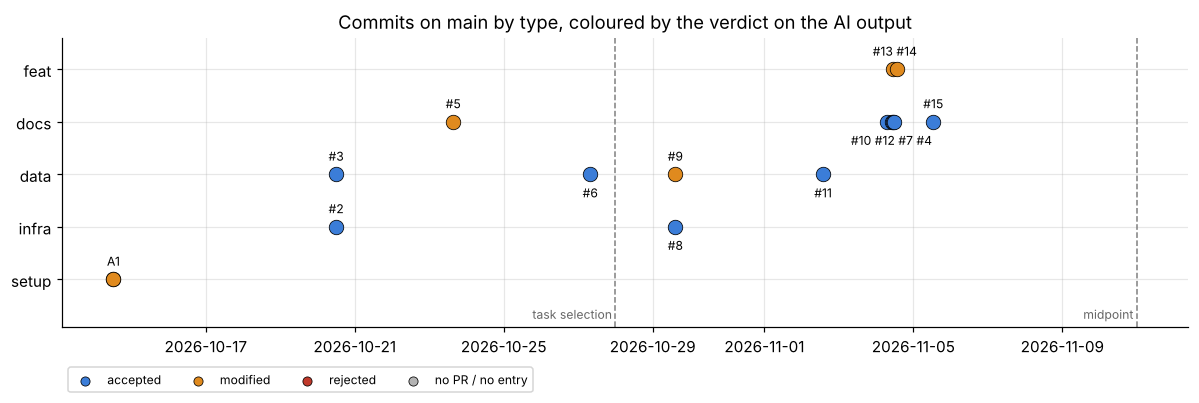

In [4]:
colors = {"accepted": "#3b7dd8", "modified": "#e08a1e", "rejected": "#c0392b"}
order = ["setup", "infra", "data", "docs", "feat"]
fig, ax = plt.subplots(figsize=(11, 3.8))
for n, (_, r) in enumerate(commits.iterrows()):
    v = prs.loc[prs.hash == r.hash, "verdict"]
    v = v.iloc[0] if len(v) else None
    y = order.index(r.prefix) if r.prefix in order else 0
    ax.scatter(r.date, y, s=90, color=colors.get(v, "0.7"), edgecolor="black", lw=0.5, zorder=3)
for d, label in [("2026-10-28", "task selection"), ("2026-11-11", "midpoint")]:
    ax.axvline(pd.Timestamp(d), color="0.5", ls="--", lw=1)
    ax.text(pd.Timestamp(d), -0.75, label + " ", fontsize=8, ha="right", color="0.4")
ax.set_yticks(range(len(order)), order); ax.set_ylim(-0.9, len(order) - 0.4)
labelled = commits.dropna(subset=["pr"]).assign(day=lambda d: d.date.dt.date,
                                                label=lambda d: np.where(d.pr == 0, "A1", "#" + d.pr.astype(int).astype(str)))
seen = {}
for (day, prefix), grp in labelled.groupby(["day", "prefix"]):
    n = seen[prefix] = seen.get(prefix, -1) + 1   # alternate above/below within one row
    y = order.index(prefix) if prefix in order else 0
    ax.annotate(" ".join(grp.label), (grp.date.mean(), y), xytext=(0, 9 if n % 2 == 0 else -15),
                textcoords="offset points", ha="center", fontsize=8)
ax.set_title("Commits on main by type, coloured by the verdict on the AI output")
for k, c in {**colors, "no PR / no entry": "0.7"}.items():
    ax.scatter([], [], color=c, label=k, edgecolor="black", lw=0.5)
ax.legend(loc="upper left", fontsize=8, ncol=4, bbox_to_anchor=(0, -0.12))
plt.tight_layout(); plt.show()

## 3 · Accepted, modified, rejected

The PR-level verdict hides the details: within one PR, single suggestions were accepted and others
rejected. The table below is the suggestion-level list from the AI log.

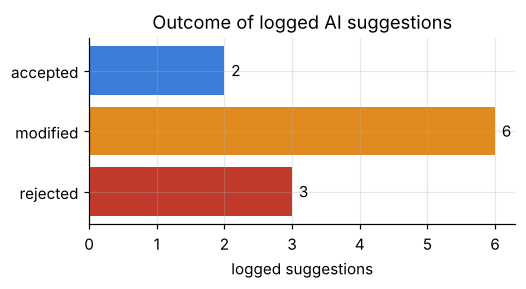

,session,suggestion,outcome,why
0,A1,TiRex-2 as the model,modified,kept as a proposal for the team
1,A3,P0 = surface pressure,rejected,it is mean sea level pressure
2,A4,synthetic covariate check,accepted,explained the flat results
3,A4,upstream stations as past covariates,rejected,no effect on the forecast
4,A5,cold-wave day = any hour,modified,only 'same hour' gives the agreed 29 days
5,A5,interpolate(limit=3),modified,fills the start of long gaps
6,A6,cold-front thresholds,accepted,"after checks on calm days, big events, wind/rain"
7,B1,jump-to at peak detection,modified,almost no point marked at that hour
8,B1,light/dark switch,rejected,broke the map
9,B1,year-long slider,modified,too coarse; day picker + hour slider


In [5]:
suggestions = pd.DataFrame([
    ("A1", "TiRex-2 as the model", "modified", "kept as a proposal for the team"),
    ("A3", "P0 = surface pressure", "rejected", "it is mean sea level pressure"),
    ("A4", "synthetic covariate check", "accepted", "explained the flat results"),
    ("A4", "upstream stations as past covariates", "rejected", "no effect on the forecast"),
    ("A5", "cold-wave day = any hour", "modified", "only 'same hour' gives the agreed 29 days"),
    ("A5", "interpolate(limit=3)", "modified", "fills the start of long gaps"),
    ("A6", "cold-front thresholds", "accepted", "after checks on calm days, big events, wind/rain"),
    ("B1", "jump-to at peak detection", "modified", "almost no point marked at that hour"),
    ("B1", "light/dark switch", "rejected", "broke the map"),
    ("B1", "year-long slider", "modified", "too coarse; day picker + hour slider"),
    ("B2", "304 spread start times", "modified", "corrected to 306"),
], columns=["session", "suggestion", "outcome", "why"])
counts = suggestions.outcome.value_counts().reindex(["accepted", "modified", "rejected"])
fig, ax = plt.subplots(figsize=(5, 2.2))
ax.barh(counts.index, counts.values, color=[colors[k] for k in counts.index])
for i, v in enumerate(counts.values):
    ax.text(v + 0.1, i, str(v), va="center")
ax.invert_yaxis(); ax.set_xlabel("logged suggestions"); ax.set_title("Outcome of logged AI suggestions")
plt.show()
suggestions

**Reading this.** The list is not a full count of every AI suggestion: it holds the ones that mattered
enough to be written down in a PR. Most AI output was code and text that was accepted after running it.
What the list does show is *where* the human checks caught problems:

- **numbers** that did not match a known value (29 cold-wave days, 306 start times, 378 points),
- **meanings** of variables (`P0`),
- **design choices** that were technically fine but wrong for the reader (jump-to hour, slider, theme).

Notebooks 01–03 replay three of these steps with code.